<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">44 European Football Leagues — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">Every figure of the listing, recomputed from the files of the full product:
92,640 matches from the top division of 44 European countries, 132,127,449 timestamped quotes from 5 named
bookmakers incl. Pinnacle, 4,705,326 snapshots from 37 more bookmakers, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/aplpqd?utm_source=github&utm_medium=notebook&utm_campaign=oel_premium&utm_content=notebook_top)** · free 47-match sample: same files, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

def find_root():
    """Folder of the full product: the OtherEurope_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("OEL_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "OtherEurope_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("OtherEurope_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 44 per-league files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "OtherEurope_Odds_Timestamped_"),
                                        ("snapshots", "OtherEurope_Bookmaker_Snapshots_"),
                                        ("events", "OtherEurope_Events_"), ("lineups", "OtherEurope_Lineups_"),
                                        ("minute_stats", "OtherEurope_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 44 for fs in FILES.values()), \
    "each table should have 44 files, one per league: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
BOOK_COLOR = {"Bet365": "#00d4ff", "Pinnacle": "#f0c75e", "Unibet": "#7bd88f", "Betfair": "#d55181", "Betsson": "#b59cff"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]

Product folder: /tmp/claude-0/-home-claude/13728760-8122-5997-9130-0d5309024b7b/scratchpad/oel_ref/livraison/Other_European_Leagues_Premium_2016-2026
odds          44 files  (.csv.gz)
snapshots     44 files  (.csv.gz)
events        44 files  (.csv.gz)
lineups       44 files  (.csv.gz)
minute_stats  44 files  (.csv.gz)


## 1 · The claims

Copied from the listing and the README. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.

In [2]:
CLAIMS = {
    'matches': 92_640,
    'leagues': 44,
    'league_seasons': 482,
    'first_kickoff_on': '2016-08-28',
    'last_kickoff_before': '2026-09-30T00:00:00Z',
    'matches_per_league': {
        'ALB': 1_653, 'ARM': 1_400, 'AUT': 1_934, 'AZE': 1_399, 'BEL': 2_982, 'BIH': 1_881, 'BLR': 2_354,
        'BUL': 2_594, 'CRO': 1_814, 'CYP': 2_303, 'CZE': 2_774, 'DEN': 2_172, 'EST': 1_755, 'FIN': 1_759,
        'FRO': 1_275, 'GEO': 1_736, 'GRE': 2_434, 'HUN': 1_985, 'IRL': 1_769, 'ISL': 1_459, 'ISR': 2_416,
        'KAZ': 1_839, 'LTU': 1_520, 'LUX': 2_159, 'LVA': 1_492, 'MDA': 1_149, 'MKD': 1_825, 'MLT': 1_831,
        'MNE': 1_808, 'NED': 3_100, 'NIR': 2_271, 'NOR': 2_415, 'POL': 2_977, 'ROU': 3_035, 'RUS': 2_459,
        'SCO': 2_305, 'SRB': 3_019, 'SUI': 1_970, 'SVK': 1_926, 'SVN': 1_812, 'SWE': 2_422, 'TUR': 3_402,
        'UKR': 2_076, 'WAL': 1_980,
    },
    'play_offs': 740,
    'two_legged_ties': 254,
    'extra_time': 76,
    'penalty_shootouts': 59,
    'neutral_venue': {'neutral': 0, 'home_country': 88_494, 'unknown': 4_146},
    'round_filled': 87_675,
    'quotes': 132_127_449,
    'in_play': 98_899_914,
    'pre_match': 33_227_535,
    'quotes_per_book': {
        'Bet365': 93_738_284, 'Pinnacle': 6_428_218, 'Unibet': 8_207_106, 'Betfair': 20_680_609,
        'Betsson': 3_073_232,
    },
    'ft_1x2_close_per_book': {
        'Bet365': 87_252, 'Pinnacle': 66_677, 'Unibet': 72_303, 'Betfair': 16_981, 'Betsson': 32_196,
    },
    'median_close_gap': {
        'Bet365': '27 min', 'Betfair': '6 min', 'Betsson': '11 min', 'Pinnacle': '5 min', 'Unibet': '3.0 h',
    },
    'coverage_from': {
        'Bet365': '2016-08-28', 'Pinnacle': '2018-09-27', 'Unibet': '2017-04-15', 'Betfair': '2023-11-03',
        'Betsson': '2022-07-03', 'Minute_Stats': '2017-06-12',
    },
    'coverage_gaps': {
        'Bet365': [], 'Pinnacle': [['2023-09', '2023-11'], ['2026-07', '2026-08']],
        'Unibet': [['2026-07', '2026-08']], 'Betfair': [['2024-11', '2025-08'], ['2026-07', '2026-08']],
        'Betsson': [['2026-06', '2026-08']], 'Minute_Stats': [['2018-01', '2019-09'], ['2026-06', '2026-07']],
    },
    'snapshots': 4_705_326,
    'snapshot_books': 37,
    'team_stats': 185_280,
    'lineups': 1_991_980,
    'events': 1_962_546,
    'minute_stats': 22_286_834,
    'example_in_play_bet365_1x2': 253,
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.0f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
groups = man.assign(Table=man["File"].str.replace(r"(_[A-Z]{3})?\.(csv\.gz|csv|xlsx|md)$", "", regex=True)
                                   .str.replace(r"^.*/", "", regex=True))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

229 files, 1.77 GB hashed in 2 s
PASS  all 229 files present
PASS  every SHA-256 matches the MANIFEST


,files,rows
Table,,
OtherEurope_Bookmaker_Snapshots,44,4705326
OtherEurope_Coverage,2,482
OtherEurope_Events,44,1962546
OtherEurope_Lineups,44,1991980
OtherEurope_Matches,2,92640
OtherEurope_Minute_Stats,44,22286834
OtherEurope_Odds_Timestamped,44,132127449
OtherEurope_Opening_Closing_Odds,2,92640
OtherEurope_Team_Stats,2,185280


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "OtherEurope_Matches.csv"),
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Season": str,
                       "Home_Formation": str, "Away_Formation": str})
ORDER = sorted(M["Competition_Code"].unique())
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique", M["Match_ID"].is_unique)
seasons = M[["Competition_Code", "Season"]].drop_duplicates()
check(f"{CLAIMS['leagues']} top flights (club football, division 1), {CLAIMS['league_seasons']} league-seasons",
      M["Competition_Code"].nunique() == CLAIMS["leagues"] and len(seasons) == CLAIMS["league_seasons"]
      and (M["Division"] == 1).all() and (M["Team_Type"] == "Club").all(),
      f"{M['Competition_Code'].nunique()} / {len(seasons)}")
per_league = M["Competition_Code"].value_counts().to_dict()
check("matches per league, as listed", per_league == CLAIMS["matches_per_league"],
      ", ".join(f"{c} {per_league.get(c, 0)}" for c in ORDER if per_league.get(c, 0) != CLAIMS["matches_per_league"].get(c)))
check(f"first kickoff on {CLAIMS['first_kickoff_on']}, last before {CLAIMS['last_kickoff_before'][:10]}",
      M["Kickoff_UTC"].min().startswith(CLAIMS["first_kickoff_on"]) and M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"],
      f"{M['Kickoff_UTC'].min()} to {M['Kickoff_UTC'].max()}")
check("Season reads 2016/17 (two calendar years) or 2019 (one)", M["Season"].str.fullmatch(r"\d{4}(/\d{2})?").all(),
      ", ".join(sorted(M["Season"].unique())[:4]) + "...")
po = M["Stage"] == "Play-Offs"
check(f"{CLAIMS['play_offs']:,} Play-Offs matches, {CLAIMS['two_legged_ties']} two-legged ties, Leg only in Play-Offs",
      po.sum() == CLAIMS["play_offs"] and (M["Leg"] == 1).sum() == CLAIMS["two_legged_ties"] and M.loc[~po, "Leg"].isna().all(),
      f"{po.sum():,} / {(M['Leg'] == 1).sum()}")
decider = (M["Extra_Time"] == 1) | (M["Penalty_Shootout"] == 1)
deciding = po & (M["Leg"].isna() | (M["Leg"] == 2))          # single match or second leg
check(f"extra time on {CLAIMS['extra_time']} matches, shoot-outs on {CLAIMS['penalty_shootouts']}, only in deciding Play-Offs matches",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and (M["Penalty_Shootout"] == 1).sum() == CLAIMS["penalty_shootouts"]
      and (~decider | deciding).all(),
      f"{(M['Extra_Time'] == 1).sum()} / {(M['Penalty_Shootout'] == 1).sum()}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
pens = M[M["Penalty_Shootout"] == 1]
level = pens["Home_Goals_AET"].fillna(pens["Home_Goals_90"]) == pens["Away_Goals_AET"].fillna(pens["Away_Goals_90"])
check("every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)",
      (pens["Home_Penalties"] != pens["Away_Penalties"]).all() and (level | (pens["Leg"] == 2)).all(),
      f"{level.sum()} after a level match, {(~level).sum()} after a second leg won on the day")
nv = CLAIMS["neutral_venue"]
check(f"Neutral_Venue: {nv['neutral']} neutral, {nv['home_country']:,} at home, {nv['unknown']:,} unknown venue",
      (M["Neutral_Venue"] == 1).sum() == nv["neutral"] and (M["Neutral_Venue"] == 0).sum() == nv["home_country"]
      and M["Neutral_Venue"].isna().sum() == nv["unknown"])
check(f"Round (matchday) filled on {CLAIMS['round_filled']:,} matches, never in Play-Offs",
      M["Round"].notna().sum() == CLAIMS["round_filled"] and M.loc[po, "Round"].isna().all(),
      f"{M['Round'].notna().sum():,} ({M['Round'].notna().mean():.1%})")
(seasons.groupby("Competition_Code")["Season"].agg(["count", "min", "max"])
   .join(M.drop_duplicates("Competition_Code").set_index("Competition_Code")[["Country", "Competition"]])
   .join(M["Competition_Code"].value_counts().rename("matches"))
   .join(M[po].groupby("Competition_Code").size().rename("play_offs")).fillna({"play_offs": 0})
   .astype({"play_offs": int})
   .rename(columns={"count": "seasons", "min": "first", "max": "last"})
   [["Country", "Competition", "seasons", "first", "last", "matches", "play_offs"]])

PASS  92,640 matches   [92,640]
PASS  Match_ID is unique
PASS  44 top flights (club football, division 1), 482 league-seasons   [44 / 482]
PASS  matches per league, as listed
PASS  first kickoff on 2016-08-28, last before 2026-09-30   [2016-08-28T10:00:00Z to 2026-09-29T18:45:00Z]
PASS  Season reads 2016/17 (two calendar years) or 2019 (one)   [2016, 2016/17, 2017, 2017/18...]
PASS  740 Play-Offs matches, 254 two-legged ties, Leg only in Play-Offs   [740 / 254]
PASS  extra time on 76 matches, shoot-outs on 59, only in deciding Play-Offs matches   [76 / 59]
PASS  Result_90 agrees with the 90-minute score on every match
PASS  every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)   [46 after a level match, 13 after a second leg won on the day]
PASS  Neutral_Venue: 0 neutral, 88,494 at home, 4,146 unknown venue
PASS  Round (matchday) filled on 87,675 matches, never in Play-Offs   [87,675 (94.6%)]


,Country,Competition,seasons,first,last,matches,play_offs
Competition_Code,,,,,,,
ALB,Albania,Kategoria Superiore,10,2017/18,2026/27,1653,10
ARM,Armenia,Armenian Premier League,11,2016/17,2026/27,1400,0
AUT,Austria,Austrian Bundesliga,11,2016/17,2026/27,1934,24
AZE,Azerbaijan,Azerbaijan Premier League,11,2016/17,2026/27,1399,1
BEL,Belgium,Belgian Pro League,11,2016/17,2026/27,2982,14
BIH,Bosnia & Herzegovina,Premier League of Bosnia and Herzegovina,11,2016/17,2026/27,1881,0
BLR,Belarus,Belarusian Premier League,11,2016,2026,2354,0
BUL,Bulgaria,Bulgarian First League,11,2016/17,2026/27,2594,52
CRO,Croatia,Croatian First Football League,11,2016/17,2026/27,1814,11


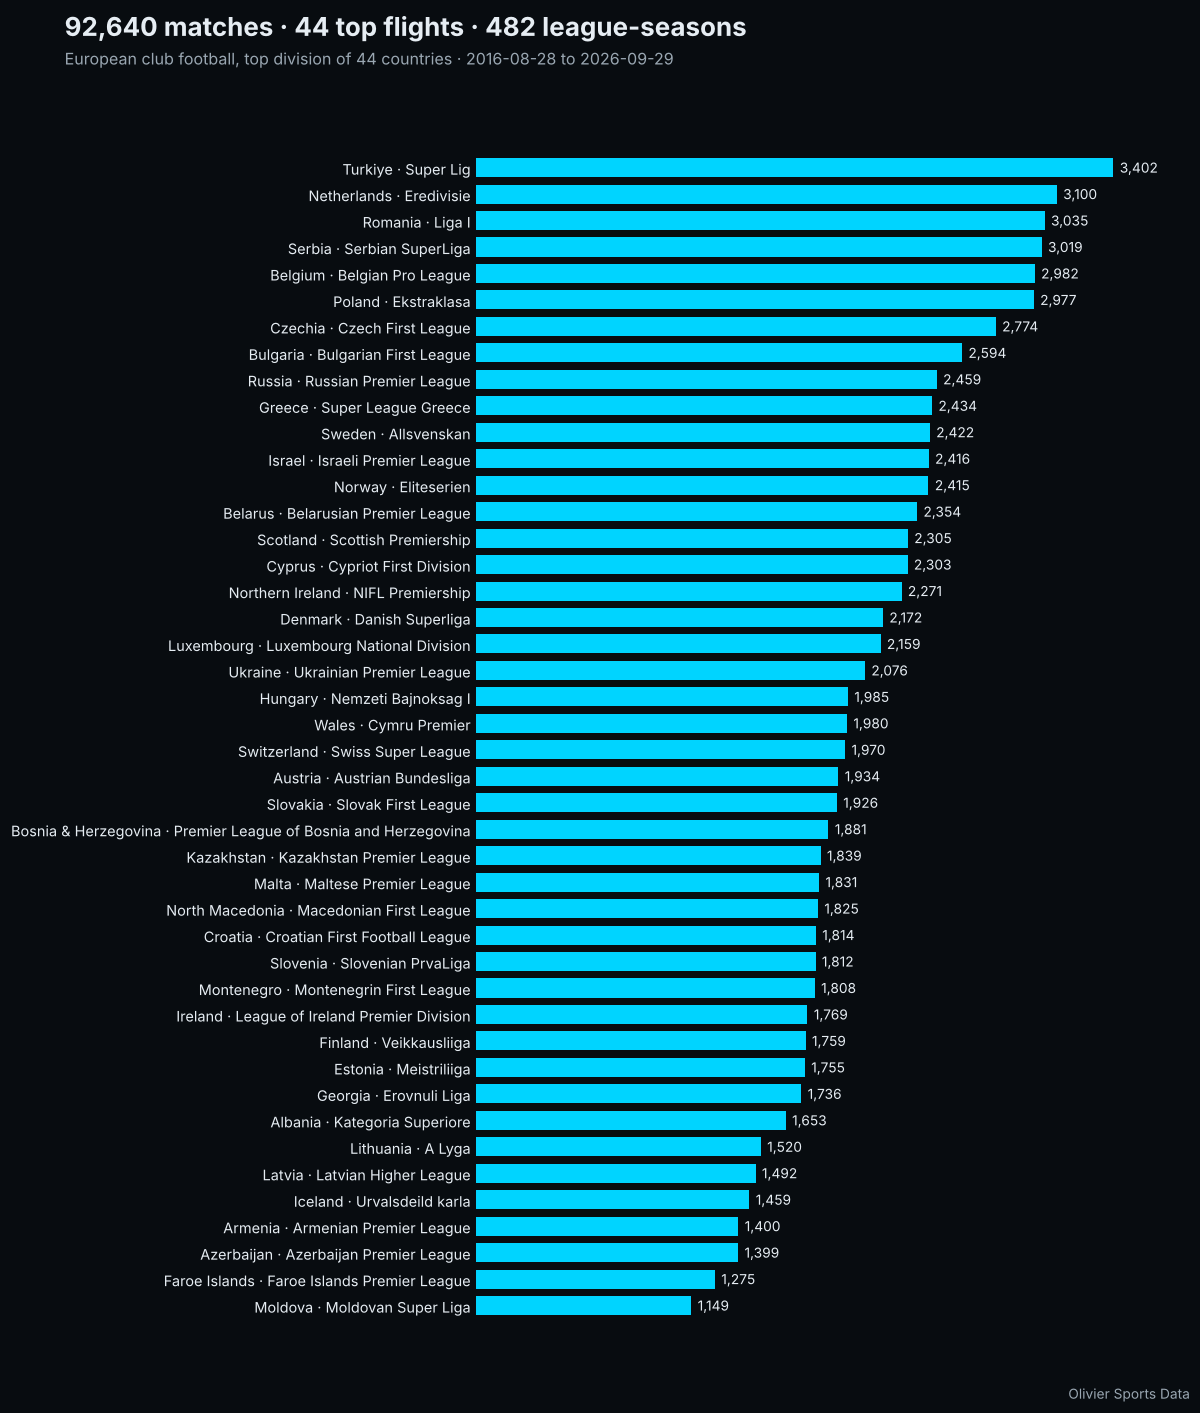

In [5]:
# matches per league (also saved as a PNG: Output tab on Kaggle)
names = M.drop_duplicates("Competition_Code").set_index("Competition_Code")
counts = M["Competition_Code"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(11, 13))
fig.subplots_adjust(left=0.36, right=0.95, top=0.92, bottom=0.03)
ax.barh(range(len(counts)), counts.values, height=0.72, color=CYAN, zorder=2)
ax.set_yticks(range(len(counts)), [f"{names.loc[c, 'Country']} · {names.loc[c, 'Competition']}" for c in counts.index],
              fontsize=9.5, color=FG)
for i, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, i, f"{v:,}", va="center", fontsize=9, color=FG)
ax.set_xlim(0, counts.max() * 1.12)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.965, f"{len(M):,} matches · {M['Competition_Code'].nunique()} top flights · {len(seasons)} league-seasons",
         fontsize=17, fontweight="bold", color=FG)
fig.text(0.02, 0.945, f"European club football, top division of 44 countries · "
         f"{M['Kickoff_UTC'].min()[:10]} to {M['Kickoff_UTC'].max()[:10]}", fontsize=10.5, color=FG2)
fig.text(0.95, 0.012, "Olivier Sports Data", ha="right", fontsize=9, color=FG2)
fig.savefig("matches_per_league.png", dpi=170, facecolor=BG)
plt.show()

## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [6]:
head = pd.read_csv(os.path.join(ROOT, "OtherEurope_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "OtherEurope_Opening_Closing_Odds.csv"),
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Season")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")

cov = {b: int(OC[f"{b}_FT_1X2_Close_Time"].notna().sum()) for b in BOOKS}
check("matches with a FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches


PASS  all 955,379 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with a FT 1X2 close, per book, as listed   [Bet365 87,252 · Pinnacle 66,677 · Unibet 72,303 · Betfair 16,981 · Betsson 32,196]


### Coverage by league — share of matches with a FT 1X2 closing price

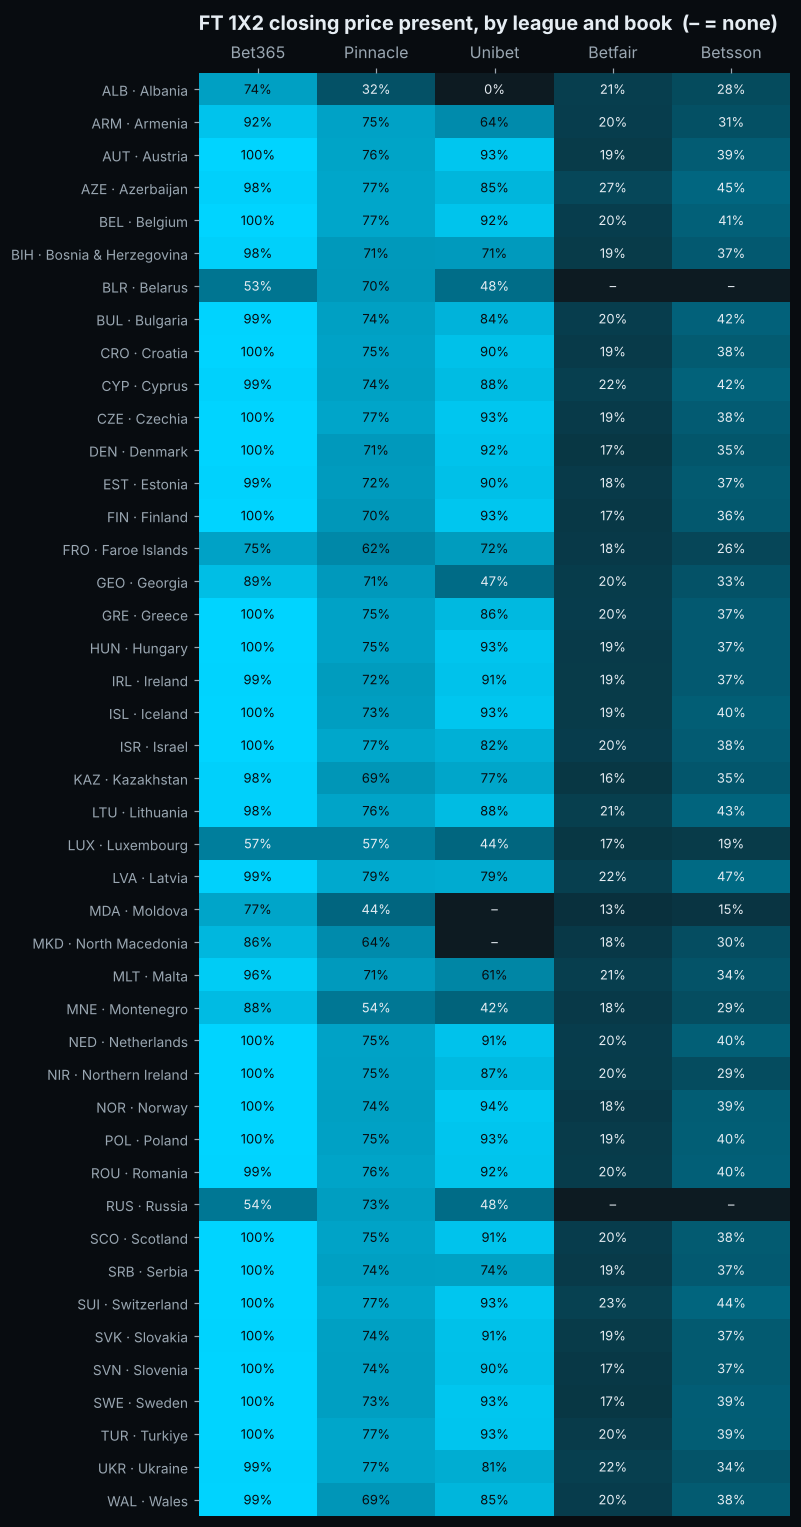

In [7]:
share = pd.DataFrame({b: OC.groupby("Competition_Code")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean())
                      for b in BOOKS}).reindex(ORDER)
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(7.4, 14))
ax.imshow(share.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BOOKS)), BOOKS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)), [f"{c} · {names.loc[c, 'Country']}" for c in ORDER], fontsize=9)
ax.grid(False)
for i, c in enumerate(ORDER):
    for j, b in enumerate(BOOKS):
        v = share.loc[c, b]
        ax.text(j, i, "–" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by league and book  (– = none)", pad=28)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### When is each book in the files?

The README's *Coverage over time* table, recomputed: the share of matches with a FT 1X2 closing price, month by
month (leagues where the book was collected), and the same for minute-by-minute statistics. A gap is a month with at
least 100 matches in which fewer than half of the matches have it, after the first month that reaches one half.

PASS  first match with each book (FT 1X2 close) and with minute stats, as listed   [Bet365 2016-08-28 · Pinnacle 2018-09-27 · Unibet 2017-04-15 · Betfair 2023-11-03 · Betsson 2022-07-03 · Minute_Stats 2017-06-12]
PASS  months with a gap, as listed   [Bet365 none · Pinnacle 2023-09..2023-11, 2026-07..2026-08 · Unibet 2026-07..2026-08 · Betfair 2024-11..2025-08, 2026-07..2026-08 · Betsson 2026-06..2026-08 · Minute_Stats 2018-01..2019-09, 2026-06..2026-07]


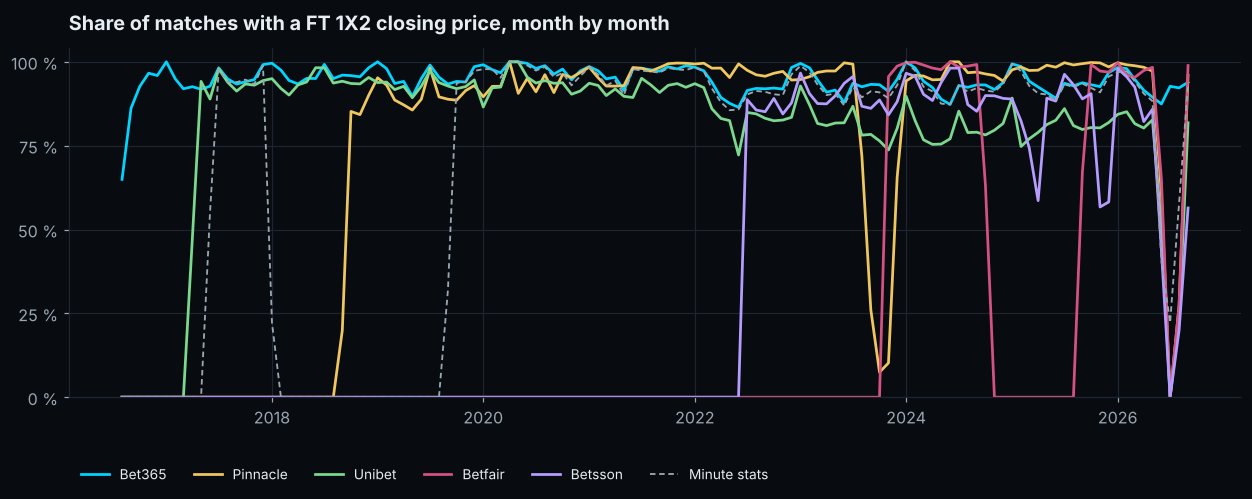

In [8]:
NOT_COLLECTED = {"BLR": ["Betfair", "Betsson"], "RUS": ["Betfair", "Betsson"], "MDA": ["Unibet"], "MKD": ["Unibet"]}
month = OC["Kickoff_UTC"].str[:7]
has_ms = M.set_index("Match_ID")["Has_Minute_Stats"].reindex(OC["Match_ID"]).to_numpy() == 1
series = {b: (OC[f"{b}_FT_1X2_Close_Time"].notna().to_numpy(),
              ~OC["Competition_Code"].isin([c for c, bs in NOT_COLLECTED.items() if b in bs]).to_numpy()) for b in BOOKS}
series["Minute_Stats"] = (has_ms, np.ones(len(OC), bool))

def coverage_over_time(present, scope, threshold=0.5, min_matches=100):
    d = pd.DataFrame({"month": month[scope].to_numpy(), "ok": present[scope]})
    first = OC.loc[scope & present, "Kickoff_UTC"].min()[:10]
    g = d.groupby("month")["ok"].agg(["size", "mean"])
    states = [(m, r["mean"] >= threshold) for m, r in g.iterrows() if r["size"] >= min_matches]
    while states and not states[0][1]:
        states.pop(0)
    gaps, cur = [], None
    for m, ok in states:
        if not ok:
            cur = [m, m] if cur is None else [cur[0], m]
        elif cur:
            gaps.append(cur); cur = None
    if cur:
        gaps.append(cur)
    return first, gaps, g["mean"]

timeline, got_from, got_gaps = {}, {}, {}
for name, (present, scope) in series.items():
    got_from[name], got_gaps[name], timeline[name] = coverage_over_time(present, scope)
check("first match with each book (FT 1X2 close) and with minute stats, as listed", got_from == CLAIMS["coverage_from"],
      " · ".join(f"{k} {v}" for k, v in got_from.items()))
check("months with a gap, as listed", got_gaps == CLAIMS["coverage_gaps"],
      " · ".join(f"{k} " + (", ".join(a if a == b else f"{a}..{b}" for a, b in v) or "none") for k, v in got_gaps.items()))

fig, ax = plt.subplots(figsize=(11.5, 4.8))
for name in BOOKS:
    s = timeline[name]
    ax.plot(pd.to_datetime(s.index), s.values, color=BOOK_COLOR[name], linewidth=1.8, label=name)
s = timeline["Minute_Stats"]
ax.plot(pd.to_datetime(s.index), s.values, color=FG2, linewidth=1.2, linestyle=(0, (3, 2)), label="Minute stats")
ax.set_ylim(0, 1.04)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_title("Share of matches with a FT 1X2 closing price, month by month", pad=12)
ax.legend(loc="lower left", ncol=6, fontsize=9, bbox_to_anchor=(0, -0.28))
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 5 min · Betfair 6 min · Betsson 11 min · Bet365 27 min · Unibet 3.0 h]


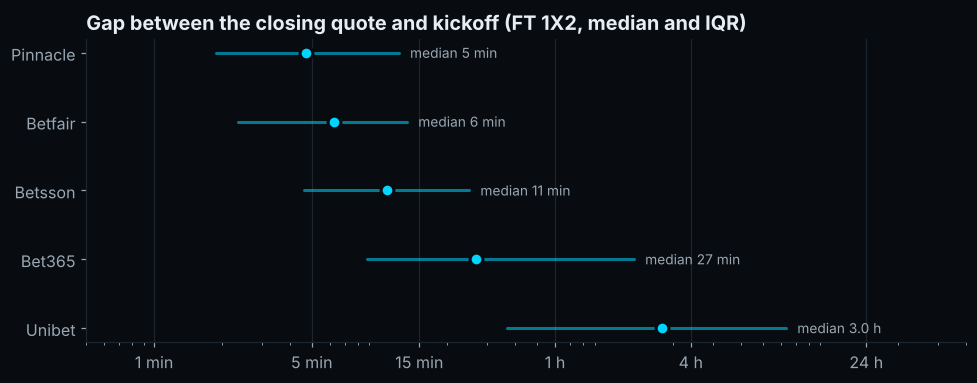

In [9]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [10]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"87,252",0.9691,0.9576,9.22%,8.32%
Pinnacle,"66,677",0.9684,0.9588,6.80%,5.13%
Unibet,"72,303",0.9690,0.9618,9.33%,9.23%
Betfair,"16,981",0.9790,0.9678,9.41%,11.97%
Betsson,"32,196",0.9702,0.9644,7.82%,7.82%


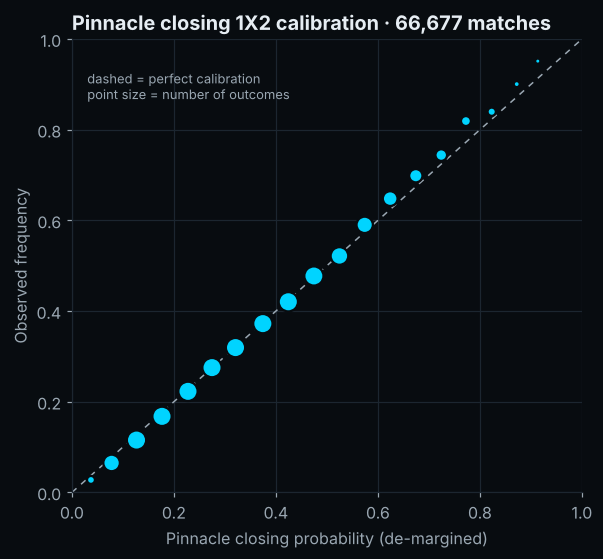

In [11]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 60, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 132 million timestamped quotes

One pass over the 44 odds files, a few columns at a time. Checked on every row: a **pre-match** quote carries no
score and was recorded before the scheduled kickoff.

In [12]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
comp_by_id = pd.Series(M["Competition_Code"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Score_Home"]

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

t0 = time.time()
by_book_phase, by_book_league = [], []
pre_scored = pre_late = inplay_scored = n_rows = 0
off_manifest = []
for f in FILES["odds"]:
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = (d["Phase"] == "Pre-match").to_numpy()
    scored = d["Score_Home"].notna().to_numpy()
    pre_scored += (pre & scored).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    inplay_scored += (~pre & scored).sum()
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_league.append(d.groupby([d["Book"], comp_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    print(f"{os.path.basename(f):45} {len(d):>12,} quotes   {time.time() - t0:5.0f} s")
    del d

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", {b: int(n) for b, n in bp.sum(axis=1).items()} == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
print(f"in-play quotes with the score attached: {inplay_scored / phase.get('In-play', 1):.1%}")
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

OtherEurope_Odds_Timestamped_ALB.csv.gz            974,919 quotes       1 s


OtherEurope_Odds_Timestamped_ARM.csv.gz          1,292,503 quotes       1 s


OtherEurope_Odds_Timestamped_AUT.csv.gz          3,051,792 quotes       3 s


OtherEurope_Odds_Timestamped_AZE.csv.gz          1,982,104 quotes       4 s


OtherEurope_Odds_Timestamped_BEL.csv.gz          5,579,157 quotes       8 s


...

OtherEurope_Odds_Timestamped_SWE.csv.gz          4,603,598 quotes      72 s


OtherEurope_Odds_Timestamped_TUR.csv.gz          6,583,391 quotes      76 s


OtherEurope_Odds_Timestamped_UKR.csv.gz          3,090,002 quotes      78 s


OtherEurope_Odds_Timestamped_WAL.csv.gz          2,405,515 quotes      80 s
PASS  132,127,449 quotes, every file equal to the MANIFEST   [132,127,449]
PASS  in-play / pre-match split as listed   [98,899,914 in-play · 33,227,535 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]
in-play quotes with the score attached: 96.1%


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"84,215,350","9,522,934","93,738,284"
Pinnacle,"554,626","5,873,592","6,428,218"
Unibet,"7,666,980","540,126","8,207,106"
Betfair,"4,276,072","16,404,537","20,680,609"
Betsson,"2,186,886","886,346","3,073,232"


Quotes per match, all markets, by league: how often each book updated its prices.

In [13]:
bl = pd.concat(by_book_league).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(index=ORDER, columns=BOOKS)
matches_per_league = M.groupby("Competition_Code").size()
(bl.div(matches_per_league, axis=0)).round(0).astype(int).rename_axis("Quotes per match").style.format("{:,}")

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Quotes per match,,,,,
ALB,467,16,0,88,18
ARM,670,42,69,112,30
AUT,"1,067",85,108,287,31
AZE,"1,080",45,78,174,39
BEL,"1,262",103,138,326,41
BIH,952,40,58,112,28
BLR,560,77,55,0,0
BUL,"1,034",70,109,309,39
CRO,"1,152",76,91,257,32


### 37 more bookmakers: dated snapshots

`Bookmaker_Snapshots` holds the first price the source kept for each other bookmaker (`Open`) and its latest
snapshot that is still pre-match (`Last_Pre_Match`). A dated snapshot, not a closing price: the minutes before
kickoff are given on every row.

In [14]:
ids = set(M["Match_ID"].astype("int64"))
parts, off = [], []
for f in FILES["snapshots"]:
    d = read(f, ["Match_ID", "Book", "Market", "Snapshot", "Minutes_Before_Kickoff"])
    if len(d) != ROWS.get(stem(f)):
        off.append(stem(f))
    parts.append(d)
S = pd.concat(parts, ignore_index=True); del parts
check(f"{CLAIMS['snapshots']:,} snapshot rows, all joined to a match", len(S) == CLAIMS["snapshots"] and S["Match_ID"].isin(ids).all()
      and not off, f"{len(S):,}" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['snapshot_books']} bookmakers, none of the 5 main books",
      S["Book"].nunique() == CLAIMS["snapshot_books"] and not set(S["Book"]) & set(BOOKS + ["Betfair (Sportsbook)"]),
      f"{S['Book'].nunique()} books")
check("every snapshot is pre-match (Minutes_Before_Kickoff >= 0)", (S["Minutes_Before_Kickoff"] >= 0).all())
last = S[S["Snapshot"] == "Last_Pre_Match"]
print(f"{S['Match_ID'].nunique():,} matches, {S.groupby('Match_ID')['Book'].nunique().mean():.1f} bookmakers per match on average")
(last.groupby("Market")["Minutes_Before_Kickoff"]
     .agg(rows="size", median_minutes_before_kickoff="median",
          within_60_min=lambda s: f"{(s <= 60).mean():.0%}", over_24_h=lambda s: f"{(s > 1440).mean():.0%}"))

PASS  4,705,326 snapshot rows, all joined to a match   [4,705,326]


PASS  37 bookmakers, none of the 5 main books   [37 books]
PASS  every snapshot is pre-match (Minutes_Before_Kickoff >= 0)


88,188 matches, 13.2 bookmakers per match on average


,rows,median_minutes_before_kickoff,within_60_min,over_24_h
Market,,,,
FT_1X2,1135264,90.0,46%,24%
FT_Asian_Handicap,463810,239.0,41%,31%
FT_Total_Goals,753859,154.0,42%,28%


### Lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `OtherEurope_Matches` on `Match_ID`.

In [15]:
for folder, claim in (("lineups", "lineups"), ("events", "events"), ("minute_stats", "minute_stats")):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, ["Match_ID"])
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[claim]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[claim] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))

PASS  1,991,980 lineups rows, all joined to a match   [1,991,980 rows, 0 without a match]


PASS  1,962,546 events rows, all joined to a match   [1,962,546 rows, 0 without a match]


PASS  22,286,834 minute stats rows, all joined to a match   [22,286,834 rows, 0 without a match]


## 6 · One match, quote by quote

The match shown in the listing: Celtic 1-3 Rangers, Scottish Premiership,
3 January 2026. Bet365 full-time 1X2 in play, recomputed here from `OtherEurope_Odds_Timestamped_SCO.csv.gz`, then
drawn as implied probabilities, with the goals of the events table on top. The events table counts the minute being
played (a goal at 49:20 is 50'), Bet365's clock counts the minutes elapsed (49), so a price jump usually sits about
one minute left of its dotted line. Clocks are delivered as the bookmaker sent them, never adjusted.

In [16]:
MID = 10132409
row = M[M["Match_ID"] == str(MID)].iloc[0]
check("the Matches row: Celtic 1-0 at half-time, 1-3 after 90 minutes, home ground",
      (row["Home_Goals_HT"], row["Away_Goals_HT"], row["Home_Goals_90"], row["Away_Goals_90"], row["Neutral_Venue"])
      == (1, 0, 1, 3, 0))
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
sco = read(next(f for f in FILES["odds"] if stem(f).endswith("_SCO")), cols)
one = sco[sco["Match_ID"] == MID]
del sco
print(one.groupby(["Book", "Phase"]).size().unstack(fill_value=0))
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)
check(f"{CLAIMS['example_in_play_bet365_1x2']} in-play Bet365 1X2 quotes on this match",
      len(t) == CLAIMS["example_in_play_bet365_1x2"], f"{len(t)}")

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep[:16], ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
show

PASS  the Matches row: Celtic 1-0 at half-time, 1-3 after 90 minutes, home ground


Phase     In-play  Pre-match
Book                        
Bet365       1867        349
Betfair       210        126
Betsson       154         35
Pinnacle        0        296
Unibet        150         17
PASS  253 in-play Bet365 1X2 quotes on this match   [253]


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away,Suspended
0,2026-01-03T12:32:16Z,<NA>,0,0,1.727,4.20,4.333,0
67,2026-01-03T12:50:38Z,18,0,0,1.833,3.75,3.750,0
68,2026-01-03T12:51:52Z,19,1,0,1.285,5.50,9.500,0
117,2026-01-03T13:19:14Z,47,1,0,1.285,5.00,11.000,0
118,2026-01-03T13:19:18Z,47,1,1,NaN,NaN,NaN,1
119,2026-01-03T13:19:57Z,45,1,0,1.300,5.00,11.000,0
142,2026-01-03T13:41:07Z,50,1,0,1.285,5.00,13.000,0
143,2026-01-03T13:41:12Z,50,1,1,NaN,NaN,NaN,1
174,2026-01-03T13:49:11Z,58,1,1,2.250,2.40,5.000,0
175,2026-01-03T13:49:45Z,58,1,2,NaN,NaN,NaN,1


 Minute  Added_Time Team_Side   Player
   20.0         NaN      Home     Yang
   50.0         NaN      Away Chermiti
   59.0         NaN      Away Chermiti
   71.0         NaN      Away    Moore


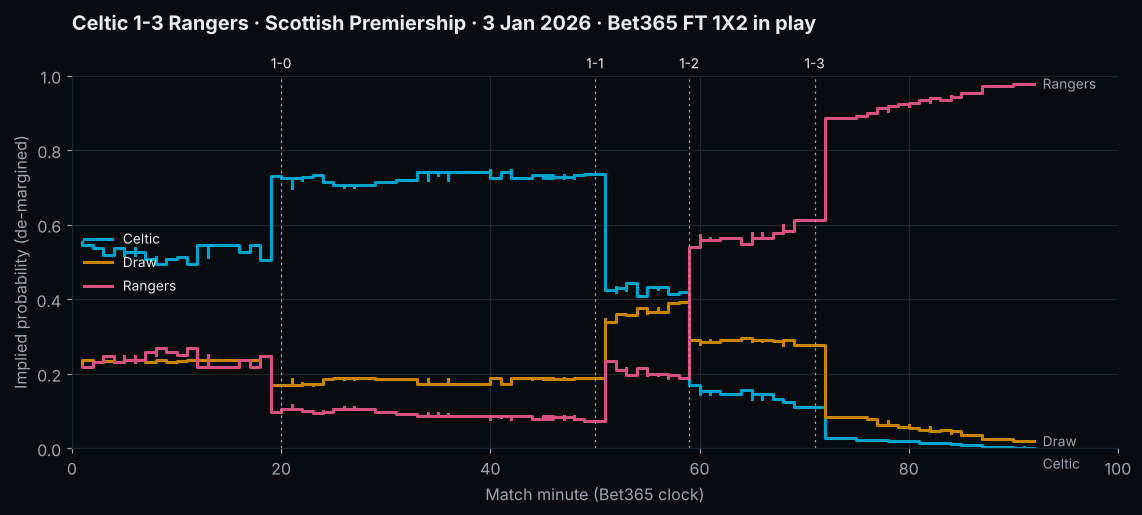

In [17]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_SCO")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
goals = ev[(ev["Match_ID"] == MID) & (ev["Event_Type"] == "Goal")].sort_values(["Minute", "Added_Time"], na_position="first")
print(goals[["Minute", "Added_Time", "Team_Side", "Player"]].to_string(index=False))

live = t[t["Suspended"] == 0].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names_hda = {"Price_Home": "Celtic", "Price_Draw": "Draw", "Price_Away": "Rangers"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names_hda[col], drawstyle="steps-post")
ends = sorted(((prob[col].iloc[-1], col) for col in prob.columns), reverse=True)
y_lab = []
for v, col in ends:                                   # end labels kept at least 0.06 apart
    y_lab.append(min(v, y_lab[-1] - 0.06) if y_lab else v)
    ax.text(x.iloc[-1] + 0.8, y_lab[-1], names_hda[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
previous, level = -99, 0
for _, g in goals.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    level = 1 - level if m - previous < 5 else 0          # stagger labels of goals close together
    previous = m
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02 + 0.06 * level, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG,
            transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("Celtic 1-3 Rangers · Scottish Premiership · 3 Jan 2026 · Bet365 FT 1X2 in play", pad=30)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, seasons read 2016/17 or 2019, and no
text cell starts with a character a spreadsheet would read as a formula or turn into a date.

In [18]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "OtherEurope_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M, OC, TS) for c in df.columns if is_text(df[c])
                        and not c.endswith(("_Open_Time", "_Close_Time", "_UTC"))])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))

PASS  formations are digits that add up to 10 players   [47,111 formations, e.g. 4231]


PASS  every timestamp is ISO 8601 with T and Z   [2,003,398 cells]


PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [6,715,264 text cells]
PASS  185,280 team-stat rows, two per match


## 8 · Summary

In [19]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

39 / 39 claims verified


Result,Claim,Detail
PASS,all 229 files present,
PASS,every SHA-256 matches the MANIFEST,
PASS,"92,640 matches","92,640"
PASS,Match_ID is unique,
PASS,"44 top flights (club football, division 1), 482 league-seasons",44 / 482
PASS,"matches per league, as listed",
PASS,"first kickoff on 2016-08-28, last before 2026-09-30",2016-08-28T10:00:00Z to 2026-09-29T18:45:00Z
PASS,Season reads 2016/17 (two calendar years) or 2019 (one),"2016, 2016/17, 2017, 2017/18..."
PASS,"740 Play-Offs matches, 254 two-legged ties, Leg only in Play-Offs",740 / 254
PASS,"extra time on 76 matches, shoot-outs on 59, only in deciding Play-Offs matches",76 / 59


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the seasons and stages of every league, the coverage tables (by league, by book, over time), the removed source
events with their evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/aplpqd?utm_source=github&utm_medium=notebook&utm_campaign=oel_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*